In [2]:
#necessary libraries
import os# Find files in folders
import numpy as np         
import librosa # Load and process audio
import matplotlib.pyplot as plt  
from tensorflow import keras 

In [3]:
# Clips containing Capuchin bird calls path
pos_dir = "Parsed_Capuchinbird_Clips"

# Clips without Capuchin bird calls path
neg_dir = "Parsed_Not_Capuchinbird_Clips"

# Long recordings we will check after training
forest_dir = "Forest Recordings"

In [4]:
#collecting audio file paths - pos(bird) and neg(no bird)
pos_files = []
neg_files = []

# Collect the positive WAV files
for name in os.listdir(pos_dir):#listdir lists the names inside that folder
    if name.endswith(".wav"):
        path = os.path.join(pos_dir, name)#joins folder and filename into a complete path
        pos_files.append(path)

# Collect the negative WAV files
for name in os.listdir(neg_dir):
    if name.endswith(".wav"):
        path = os.path.join(neg_dir, name)
        neg_files.append(path)

print("Positive clips:", len(pos_files))
print("Negative clips:", len(neg_files))

Positive clips: 217
Negative clips: 593


In [5]:
# Put all file paths into one list and making labels to give to our model
all_files = pos_files + neg_files

# Give every positive file a 1 and every negative file a 0
labels = [1] * len(pos_files) + [0] * len(neg_files)

# Convert labels into a NumPy array for later training
labels = np.array(labels)

print("Total files:", len(all_files))
print("Total labels:", len(labels))

Total files: 810
Total labels: 810


In [6]:
# Load the first positive clip

#here, audio contains numbers representating sound wave
#sample rate is how many of these numbers represent one second
audio, sample_rate = librosa.load(
    pos_files[0],#first positive files path
    sr=16000,# break one second into 16000 numbers
)

print("Sample rate:", sample_rate)
print("Number of samples:", len(audio))
print("Duration in seconds:", len(audio) / sample_rate)# we have this recording of 2 secs as 32000(total audio numbers)/16000(one sec audio number)

# Show the first 10 numbers in the audio
print(audio[:10])#tiny sound wave numbers

Sample rate: 16000
Number of samples: 32000
Duration in seconds: 2.0
[-0.04931968 -0.06594382 -0.02797408 -0.01248763  0.02493934  0.0408138
  0.05574768  0.06126558  0.04934175  0.04331931]


In [7]:
# We want each clip to contain 48,000 samples
target_samples = 16000 * 3

# If longer than 3 seconds, keep only the first 3 seconds
audio = audio[:target_samples]

# If shorter, add silence(zeros) at the end
if len(audio) < target_samples:
    missing = target_samples - len(audio)
    audio = np.pad(audio, (0, missing))

print("Samples after padding:", len(audio))
print("Duration:", len(audio) / sample_rate)

Samples after padding: 48000
Duration: 3.0


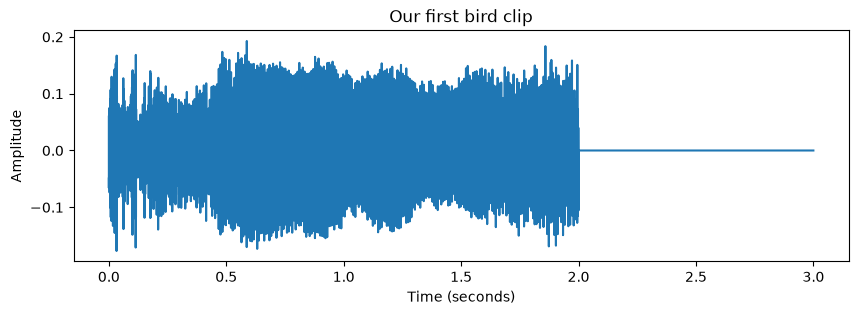

In [8]:
#plotting the first training sample
# Give each sample its time in seconds

#arange creates numbers in order so this creteas 48000 in order then we divide by 16000 to get time in seconds
time = np.arange(len(audio))/ sample_rate

plt.figure(figsize=(10, 3))
plt.plot(time, audio)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Our first bird clip")
plt.show()

In [9]:
# Turn our audio numbers into a 2D grid of sound energy
mel = librosa.feature.melspectrogram(
    y=audio, # Our audio array
    sr=sample_rate,# 16,000 samples per second
    n_mels=64,# Use 64 frequency bands
    n_fft=512, # Examine 512 audio samples at a time
    hop_length=128 # Move forward 128 samples for the next examination
)

print("Spectrogram shape:", mel.shape)


Spectrogram shape: (64, 376)


In [10]:
mel#2d array of sound energy

array([[9.9626977e-06, 2.0655654e-05, 3.4459963e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [8.4727282e-05, 1.2335130e-04, 2.6040172e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [1.2281867e-04, 1.5396203e-04, 1.8428291e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       ...,
       [4.9238930e-05, 6.1012339e-05, 1.0296934e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [8.5317472e-05, 2.5271263e-04, 4.8995874e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00],
       [2.5961599e-05, 8.8592744e-05, 1.1841640e-04, ..., 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00]], shape=(64, 376), dtype=float32)

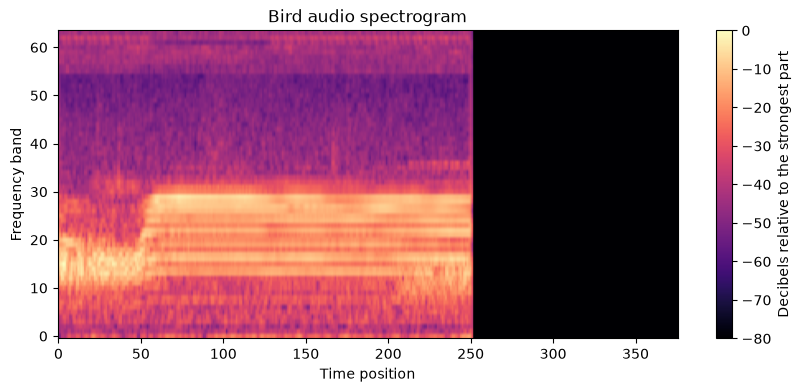

In [11]:
 # Convert sound energy to decibels so the patterns are easier to see and decibel plot
mel_db = librosa.power_to_db(mel, ref=np.max)#np.max is comparing to 0 dB as strongest and more negative means more far away from 0(decided as strong)

plt.figure(figsize=(10, 4))

# Draw the 2D array as a coloured picture
#origin = lower keeps low frequency band down at bottom
#ascept =auto stretches pic to fit graph space
plt.imshow(mel_db, origin="lower", aspect="auto", cmap="magma")
#brighter colors mean stronger sound energy 
plt.xlabel("Time position")
plt.ylabel("Frequency band")
plt.title("Bird audio spectrogram")
plt.colorbar(label="Decibels relative to the strongest part")
plt.show()

In [12]:
#putting all of above together as function we can call
def prepare_audio(file_path):
    # Load one recording
    audio, sample_rate = librosa.load(file_path, sr=16000)

    # Keep the first 3 seconds
    audio = audio[:48000]

    # Add silence if shorter than 3 seconds
    if len(audio) < 48000:
        missing = 48000 - len(audio)
        audio = np.pad(audio, (0, missing))

    # Turn the sound into a spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sample_rate,
        n_mels=64,
        n_fft=512,
        hop_length=128
    )

    # Convert power values to decibels
    mel_db = librosa.power_to_db(mel, ref=np.max)

    return mel_db

In [13]:
spectrograms = []

# Prepare one recording at a time to get all 2d arrays of decibels
for file_path in all_files:
    spectrogram = prepare_audio(file_path)
    spectrograms.append(spectrogram)

# Convert the list into one NumPy array
X = np.array(spectrograms)

print("Shape:", X.shape)

Shape: (810, 64, 376)


In [14]:
# cnn expects 3 numbers per sample like rgb we have 64,376 per sample so adding one dimension
print(X[0].shape)
X = np.expand_dims(X, axis=-1)
print("Updated Shape:", X.shape)

(64, 376)
Updated Shape: (810, 64, 376, 1)


In [15]:
#now that we have X, y(labels)---splitting into training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels#stratify deals with class imbalnce keeping bird/no bird proportion similar
)

print("Training:", len(X_train))  # 648
print("Test:", len(X_test))       # 162

Training: 648
Test: 162


In [16]:
#attaching weights as theres class imbalance
# Count each class in the training set
negative_count = np.sum(y_train == 0)
positive_count = np.sum(y_train == 1)

total = len(y_train)
#attaching weights as theres class imbalance
class_weights = {
    0: total / (2 * negative_count),#distributing half of total to negative and
    1: total / (2 * positive_count)#half of total to positive
}

print(class_weights)

{0: np.float64(0.6835443037974683), 1: np.float64(1.8620689655172413)}


In [17]:
#making the model
model = keras.Sequential([
    #X_train.shape[1:] takes the shape without the total number of recordings
    # One spectrogram: 64 rows, 376 columns, 1 channel
    keras.layers.Input(shape=X_train.shape[1:]),

    # Learn 16 patterns using small 3 × 3 filters
    keras.layers.Conv2D(16, (3, 3), activation="relu"),

    # Reduce the picture size
    keras.layers.MaxPooling2D((2, 2)),

    # Learn more patterns from the previous layer
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),

    # Turn the feature maps into one list
    keras.layers.Flatten(),

    # Combine those features to help make a decision
    keras.layers.Dense(32, activation="relu"),

    # Output a probability: close to 1 = bird, close to 0 = no bird
    keras.layers.Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=16,#process 16 samples and update the weights
    class_weight=class_weights
)

Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.4599 - loss: 11.8161
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - accuracy: 0.9614 - loss: 0.4216
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9877 - loss: 0.3622
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9892 - loss: 0.3508
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9969 - loss: 0.3248
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9938 - loss: 0.3179
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.9954 - loss: 0.3206
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9969 - loss: 0.2974
Epoch 9/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9985 - loss: 0.2866
Epoch 10/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.9969 - loss: 0.2800


In [18]:
#evaluating on testing dataset
model.evaluate(X_test, y_test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9938 - loss: 0.1514


[0.15143610537052155, 0.9938271641731262]

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


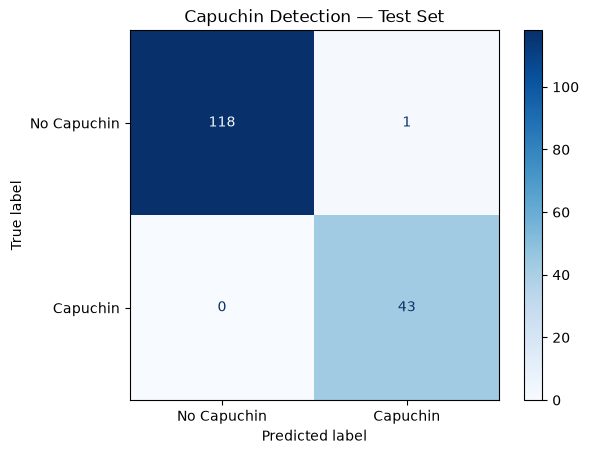

[[118   1]
 [  0  43]]


In [29]:
#making a confusion matrix for test resuts
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict the held-out test clips
probabilities = model.predict(X_test).reshape(-1)
predicted_labels = (probabilities >= 0.5).astype(int)

# Compare predictions with the correct labels
cm = confusion_matrix(y_test, predicted_labels, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Capuchin", "Capuchin"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Capuchin Detection — Test Set")
plt.show()

print(cm)

In [19]:
#getting forest files
forest_files = []

for name in os.listdir(forest_dir):
    if name.lower().endswith(".mp3"):
        path = os.path.join(forest_dir, name)
        forest_files.append(path)

print("Forest recordings:", len(forest_files))

Forest recordings: 100


In [20]:
# Load the full first forest recording
forest_audio, sample_rate = librosa.load(
    forest_files[0],
    sr=16000
)

print("File:", os.path.basename(forest_files[0]))
print("Duration in seconds:", len(forest_audio) / sample_rate)

File: recording_95.mp3
Duration in seconds: 180.0416875


In [21]:
#the recording is 3 mins,model trained on 3 secs 
#so using 3 second windows on our forest recordings
windows = []

# Move through the recording in steps of 48,000 samples
for start in range(0, len(forest_audio), 48000):
    window = forest_audio[start:start + 48000]

    # Pad the final piece if it is shorter than 3 seconds
    if len(window) < 48000:
        missing = 48000 - len(window)
        window = np.pad(window, (0, missing))

    windows.append(window)

print("Number of windows:", len(windows))

Number of windows: 61


In [22]:
# converting each window to 2d array of  decibel power
forest_spectrograms = []

for window in windows:
    mel = librosa.feature.melspectrogram(
        y=window,
        sr=16000,
        n_mels=64,
        n_fft=512,
        hop_length=128
    )

    mel_db = librosa.power_to_db(mel, ref=np.max)
    forest_spectrograms.append(mel_db)

# Convert to an array and add the one dimension
X_forest = np.array(forest_spectrograms)
X_forest = np.expand_dims(X_forest, axis=-1)

print(X_forest.shape)

(61, 64, 376, 1)


In [23]:
# predict each window using model

probabilities = model.predict(X_forest)

# Turn the column of probabilities into a simple 1D array
probabilities = probabilities.reshape(-1)

for i in range(len(probabilities)):
    print("Window", i + 1, ":", round(float(probabilities[i]), 3))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
Window 1 : 0.0
Window 2 : 0.0
Window 3 : 0.016
Window 4 : 0.579
Window 5 : 0.001
Window 6 : 0.0
Window 7 : 0.0
Window 8 : 0.0
Window 9 : 0.001
Window 10 : 0.001
Window 11 : 0.0
Window 12 : 0.0
Window 13 : 0.001
Window 14 : 0.579
Window 15 : 0.472
Window 16 : 0.0
Window 17 : 0.0
Window 18 : 0.001
Window 19 : 0.0
Window 20 : 0.001
Window 21 : 0.0
Window 22 : 0.0
Window 23 : 0.0
Window 24 : 0.001
Window 25 : 0.0
Window 26 : 0.0
Window 27 : 0.001
Window 28 : 0.005
Window 29 : 0.0
Window 30 : 0.001
Window 31 : 0.0
Window 32 : 0.0
Window 33 : 0.034
Window 34 : 0.579
Window 35 : 0.0
Window 36 : 0.0
Window 37 : 0.001
Window 38 : 0.001
Window 39 : 0.0
Window 40 : 0.001
Window 41 : 0.0
Window 42 : 0.579
Window 43 : 0.012
Window 44 : 0.001
Window 45 : 0.0
Window 46 : 0.001
Window 47 : 0.001
Window 48 : 0.0
Window 49 : 0.001
Window 50 : 0.001
Window 51 : 0.0
Window 52 : 0.0
Window 53 : 0.001
Window 54 : 0.0
Window 55 : 0.001
Window 56 : 0.001
Window 57 : 0.0
W

In [24]:
# turning probablities into 0 or 1
# 1 means predicted bird; 0 means predicted no bird
predictions = (probabilities >= 0.5).astype(int)

print(predictions)
print("Positive windows:", np.sum(predictions))

[0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
Positive windows: 5


In [25]:
# adjacent 1s may belong to same call
# so counting a new call only when we go from 0 to 1
count = 0
previous = 0

for prediction in predictions:
    # A new group starts when we go from 0 to 1
    if prediction == 1 and previous == 0:
        count += 1

    previous = prediction

print("Estimated call count:", count)

Estimated call count: 5


In [26]:
#using all above to break forest recordings into 3 secs 2d array of decibels
# and count calls that start after 0
def count_calls(file_path):
    # Load the full recording
    audio, sample_rate = librosa.load(file_path, sr=16000)

    spectrograms = []

    for start in range(0, len(audio), 48000):
        # Take one 3-second piece
        window = audio[start:start + 48000]

        # Pad the last piece if needed
        if len(window) < 48000:
            missing = 48000 - len(window)
            window = np.pad(window, (0, missing))

        # Use the same spectrogram settings as training
        mel = librosa.feature.melspectrogram(
            y=window,
            sr=sample_rate,
            n_mels=64,
            n_fft=512,
            hop_length=128
        )

        mel_db = librosa.power_to_db(mel, ref=np.max)
        spectrograms.append(mel_db)

    # Prepare the CNN input
    X_forest = np.array(spectrograms)
    X_forest = np.expand_dims(X_forest, axis=-1)

    # Predict each window
    probabilities = model.predict(X_forest, verbose=0).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    # Count groups of positive windows
    count = 0
    previous = 0

    for prediction in predictions:
        if prediction == 1 and previous == 0:
            count += 1
        previous = prediction

    return count

In [27]:
#can check any forest call capuchin call here
count = count_calls(forest_files[5])
print("Estimated calls:", count)


Estimated calls: 4


In [30]:
#counting calls of each forest recording and saving as a csv
import csv

with open("forest_predictions.csv", "w", newline="") as file:
    writer = csv.writer(file)

    # Column headings
    writer.writerow(["recording", "capuchin_calls"])

    for file_path in forest_files:
        file_name = os.path.basename(file_path)
        count = count_calls(file_path)

        writer.writerow([file_name, count])
        print(file_name, count)

print("Saved forest_predictions.csv")

recording_95.mp3 5
recording_81.mp3 5
recording_56.mp3 4
recording_42.mp3 0
recording_43.mp3 5
recording_57.mp3 4
recording_80.mp3 1
recording_94.mp3 3
recording_82.mp3 0
recording_96.mp3 1
recording_69.mp3 1
recording_41.mp3 0
recording_55.mp3 0
recording_54.mp3 3
recording_40.mp3 1
recording_68.mp3 1
recording_97.mp3 4
recording_83.mp3 0
recording_87.mp3 24
recording_93.mp3 5
recording_44.mp3 1
recording_50.mp3 0
recording_78.mp3 2
recording_79.mp3 0
recording_51.mp3 3
recording_45.mp3 3
recording_92.mp3 0
recording_86.mp3 4
recording_90.mp3 0
recording_84.mp3 2
recording_53.mp3 0
recording_47.mp3 3
recording_46.mp3 4
recording_52.mp3 0
recording_85.mp3 0
recording_91.mp3 0
recording_09.mp3 0
recording_35.mp3 0
recording_21.mp3 1
recording_20.mp3 0
recording_34.mp3 4
recording_08.mp3 25
recording_22.mp3 2
recording_36.mp3 0
recording_37.mp3 3
recording_23.mp3 5
recording_27.mp3 0
recording_33.mp3 0
recording_32.mp3 2
recording_26.mp3 2
recording_30.mp3 3
recording_24.mp3 0
recording_